# Part A: Transistor models (PTM 22nm HP, VDD = 1 V)
Trains the 4 model types (MLP, XGBoost, Random Forest, Ridge polynomial) on the 4 cases (NMOS/PMOS ON/OFF) by reusing the repo's `ML models/` code, then selects the best model per case.

In [ ]:
import subprocess, sys, pandas as pd
from pathlib import Path


from IPython.display import Image, display
REPO = Path.cwd(); MLDIR = REPO / "ML models"; DATA = REPO / "Datasets" / "data"
CASES = ["nmos_on","nmos_off","pmos_on","pmos_off"]
def run(*args):
    r = subprocess.run([sys.executable, *map(str,args)], cwd=MLDIR, capture_output=True, text=True)
    print(r.stdout[-3000:]); 
    if r.returncode: print(r.stderr[-3000:]); raise SystemExit(r.returncode)

## 1. Datasets (10,000 rows each)

In [2]:
for k in CASES:
    d = pd.read_csv(DATA/f"{k}.csv"); print(k, d.shape)
pd.read_csv(DATA/"nmos_on.csv").head()

nmos_on (10000, 16)
nmos_off (10000, 16)
pmos_on (10000, 16)
pmos_off (10000, 16)


,vdd,temp,w,vd,vs,vg,vb,vth0,toxe,ndep,u0,xj,id,ig,is,ib
0,1.024570,56.1498,2.585180e-08,0.616965,0.463955,1.024570,0,0.467118,1.051570e-09,5.966650e+18,0.040655,6.779640e-09,2.193270e-06,1.128870e-12,-2.193280e-06,-4.381060e-14
1,1.096130,11.3158,1.359570e-07,0.435355,0.389835,1.096130,0,0.498745,1.109140e-09,6.006110e+18,0.038792,6.924170e-09,2.055190e-05,2.789750e-11,-2.055200e-05,-2.902520e-13
2,1.022300,17.1965,8.898000e-08,0.833386,0.125904,1.022300,0,0.528492,1.135470e-09,5.430850e+18,0.041088,6.862820e-09,1.222350e-04,6.837620e-11,-1.222350e-04,-2.660030e-11
3,1.034480,30.5137,2.763380e-08,0.736027,0.125051,1.034480,0,0.524214,9.580520e-10,6.048370e+18,0.042097,7.759280e-09,2.959370e-05,1.753620e-11,-2.959370e-05,-7.468070e-12
4,0.928478,119.3830,3.729950e-08,0.832342,0.603697,0.928478,0,0.464014,1.051020e-09,5.062410e+18,0.038755,7.726380e-09,7.271570e-08,1.740830e-13,-7.271530e-08,-5.897000e-13


## 2. Train all 4 model types on all 4 cases (70/15/15 split, fixed seed)

### mlp

In [3]:
run("mlp/train.py", "--data-dir", DATA)


=== nmos_on: 10000 rows | dataset KCL residual / largest current: median 4.7e-07, max 1.9e-02
  mlp (60.1s)
    validation: R2(log) 0.9986  median 0.574%  p95 3.654%
    test:       R2(log) 0.9998  median 0.570%  p95 3.423%

=== nmos_off: 10000 rows | dataset KCL residual / largest current: median 8.2e-07, max 9.5e-06
  mlp (65.8s)
    validation: R2(log) 0.9962  median 0.628%  p95 4.320%
    test:       R2(log) 0.9980  median 0.699%  p95 5.003%

=== pmos_on: 10000 rows | dataset KCL residual / largest current: median 4.9e-09, max 6.7e-03
  mlp (70.8s)
    validation: R2(log) 0.9996  median 0.458%  p95 2.248%
    test:       R2(log) 1.0000  median 0.452%  p95 2.267%

=== pmos_off: 10000 rows | dataset KCL residual / largest current: median 5.0e-04, max 1.8e-01
  mlp (64.1s)
    validation: R2(log) 0.7537  median 8.613%  p95 608.214%
    test:       R2(log) 0.7569  median 8.885%  p95 537.659%

Saved models to C:\IIITH Academic\SEM 5\Digital VLSI Design\repo\ML models\mlp\saved_models
S

### xgboost_regressor

In [4]:
run("xgboost_regressor/train.py", "--data-dir", DATA)


=== nmos_on: 10000 rows | dataset KCL residual / largest current: median 4.7e-07, max 1.9e-02
  xgb (9.7s)
    validation: R2(log) 0.9984  median 4.653%  p95 26.875%
    test:       R2(log) 0.9981  median 4.655%  p95 26.611%

=== nmos_off: 10000 rows | dataset KCL residual / largest current: median 8.2e-07, max 9.5e-06
  xgb (14.1s)
    validation: R2(log) 0.9847  median 2.807%  p95 41.047%
    test:       R2(log) 0.9835  median 3.070%  p95 42.984%

=== pmos_on: 10000 rows | dataset KCL residual / largest current: median 4.9e-09, max 6.7e-03
  xgb (10.5s)
    validation: R2(log) 0.9974  median 6.190%  p95 31.060%
    test:       R2(log) 0.9982  median 6.241%  p95 30.487%

=== pmos_off: 10000 rows | dataset KCL residual / largest current: median 5.0e-04, max 1.8e-01
  xgb (12.5s)
    validation: R2(log) 0.8264  median 16.218%  p95 340.334%
    test:       R2(log) 0.8352  median 15.846%  p95 305.569%

Saved models to C:\IIITH Academic\SEM 5\Digital VLSI Design\repo\ML models\xgboost_reg

### random_forest

In [5]:
run("random_forest/train.py", "--data-dir", DATA)


=== nmos_on: 10000 rows | dataset KCL residual / largest current: median 4.7e-07, max 1.9e-02
  rf (24.9s)
    validation: R2(log) 0.9940  median 9.289%  p95 52.982%
    test:       R2(log) 0.9944  median 9.016%  p95 49.893%

=== nmos_off: 10000 rows | dataset KCL residual / largest current: median 8.2e-07, max 9.5e-06
  rf (32.4s)
    validation: R2(log) 0.9768  median 6.748%  p95 65.268%
    test:       R2(log) 0.9754  median 7.021%  p95 66.464%

=== pmos_on: 10000 rows | dataset KCL residual / largest current: median 4.9e-09, max 6.7e-03
  rf (26.4s)
    validation: R2(log) 0.9936  median 11.748%  p95 63.499%
    test:       R2(log) 0.9944  median 12.169%  p95 61.323%

=== pmos_off: 10000 rows | dataset KCL residual / largest current: median 5.0e-04, max 1.8e-01
  rf (31.9s)
    validation: R2(log) 0.8353  median 29.139%  p95 470.059%
    test:       R2(log) 0.8374  median 28.419%  p95 419.594%

Saved models to C:\IIITH Academic\SEM 5\Digital VLSI Design\repo\ML models\random_fores

### ridge_polynomial

In [6]:
run("ridge_polynomial/train.py", "--data-dir", DATA)


=== nmos_on: 10000 rows | dataset KCL residual / largest current: median 4.7e-07, max 1.9e-02
  ridge (5.8s)
    validation: R2(log) 0.9944  median 11.544%  p95 41.744%
    test:       R2(log) 0.9959  median 11.682%  p95 42.530%

=== nmos_off: 10000 rows | dataset KCL residual / largest current: median 8.2e-07, max 9.5e-06
  ridge (6.0s)
    validation: R2(log) 0.9565  median 14.484%  p95 74.494%
    test:       R2(log) 0.9563  median 14.475%  p95 82.207%

=== pmos_on: 10000 rows | dataset KCL residual / largest current: median 4.9e-09, max 6.7e-03
  ridge (16.8s)
    validation: R2(log) 0.9952  median 10.837%  p95 42.433%
    test:       R2(log) 0.9963  median 11.194%  p95 42.414%

=== pmos_off: 10000 rows | dataset KCL residual / largest current: median 5.0e-04, max 1.8e-01
  ridge (15.7s)
    validation: R2(log) 0.8192  median 33.871%  p95 656.814%
    test:       R2(log) 0.8203  median 33.362%  p95 570.150%

Saved models to C:\IIITH Academic\SEM 5\Digital VLSI Design\repo\ML model

## 3. Model comparison and best model per case

In [7]:
run("select_best.py", "--results-dir", REPO/"results")

nmos_on: mlp (lowest validation p95 error) -> C:\IIITH Academic\SEM 5\Digital VLSI Design\repo\results\nmos_on
nmos_off: mlp (lowest validation p95 error) -> C:\IIITH Academic\SEM 5\Digital VLSI Design\repo\results\nmos_off
pmos_on: mlp (lowest validation p95 error) -> C:\IIITH Academic\SEM 5\Digital VLSI Design\repo\results\pmos_on
pmos_off: xgb (lowest validation p95 error) -> C:\IIITH Academic\SEM 5\Digital VLSI Design\repo\results\pmos_off

Validation comparison:
    case model  r2_log  median_error_pct  p95_error_pct
nmos_off   mlp  0.9962            0.6275         4.3204
nmos_off   xgb  0.9847            2.8066        41.0475
nmos_off    rf  0.9768            6.7479        65.2678
nmos_off ridge  0.9565           14.4842        74.4945
 nmos_on   mlp  0.9986            0.5743         3.6543
 nmos_on   xgb  0.9984            4.6531        26.8754
 nmos_on ridge  0.9944           11.5442        41.7438
 nmos_on    rf  0.9940            9.2895        52.9818
pmos_off   xgb  0.8264  

## 4. Validation comparison tables

In [8]:
for k in CASES:
    print(k); display(pd.read_csv(REPO/"results"/k/"validation_comparison.csv"))

nmos_on


,case,model,train_seconds,r2_log,median_error_pct,p95_error_pct,id_r2_log,id_median_error_pct,id_p95_error_pct,ig_r2_log,ig_median_error_pct,ig_p95_error_pct,is_r2_log,is_median_error_pct,is_p95_error_pct,ib_r2_log,ib_median_error_pct,ib_p95_error_pct
0,nmos_on,mlp,60.1,0.998551,0.574290,3.654337,0.997867,0.549798,3.620713,0.999207,0.603936,6.452078,0.997168,0.552431,3.612655,0.999962,0.599799,2.569080
1,nmos_on,xgb,9.7,0.998354,4.653147,26.875376,0.998722,3.553155,27.409339,0.998663,4.541168,16.291444,0.998725,3.553374,27.364604,0.997304,8.331307,32.900949
2,nmos_on,ridge,5.8,0.994428,11.544207,41.743810,0.993295,13.691119,47.336875,0.995599,7.447400,26.039161,0.993398,13.691168,47.337189,0.995421,12.549796,40.199715
3,nmos_on,rf,24.9,0.994013,9.289471,52.981757,0.995770,7.248414,48.583031,0.994716,9.743804,34.342951,0.995833,7.273233,48.583812,0.989732,16.200136,73.229090


nmos_off


,case,model,train_seconds,r2_log,median_error_pct,p95_error_pct,id_r2_log,id_median_error_pct,id_p95_error_pct,ig_r2_log,ig_median_error_pct,ig_p95_error_pct,is_r2_log,is_median_error_pct,is_p95_error_pct,ib_r2_log,ib_median_error_pct,ib_p95_error_pct
0,nmos_off,mlp,65.8,0.996165,0.627510,4.320393,0.995660,0.666203,4.752224,0.999123,0.474272,2.689709,0.995068,0.737217,5.228731,0.994809,0.661836,5.572771
1,nmos_off,xgb,14.1,0.984719,2.806563,41.047467,0.972057,4.703082,63.243386,0.997349,2.717799,12.243188,0.977526,5.084074,58.165257,0.991943,0.305066,8.179251
2,nmos_off,rf,32.4,0.976759,6.747862,65.267784,0.956884,11.143412,94.845261,0.994759,6.890730,19.387465,0.961452,11.262209,86.590413,0.993940,0.155579,8.913090
3,nmos_off,ridge,6.0,0.956544,14.484209,74.494467,0.937807,20.834695,151.527589,0.981169,10.529203,31.879211,0.939688,20.364497,143.897516,0.967512,9.857928,41.536406


pmos_on


,case,model,train_seconds,r2_log,median_error_pct,p95_error_pct,id_r2_log,id_median_error_pct,id_p95_error_pct,ig_r2_log,ig_median_error_pct,ig_p95_error_pct,is_r2_log,is_median_error_pct,is_p95_error_pct,ib_r2_log,ib_median_error_pct,ib_p95_error_pct
0,pmos_on,mlp,70.8,0.999579,0.458067,2.247987,0.998641,0.492069,2.631309,0.999994,0.361117,1.407277,0.999821,0.492069,2.622974,0.999862,0.500803,2.172078
1,pmos_on,xgb,10.5,0.997380,6.189610,31.059738,0.996281,4.428315,25.686711,0.997902,9.181332,36.335464,0.997669,4.428315,25.695366,0.997669,8.548947,31.931664
2,pmos_on,ridge,16.8,0.995231,10.836863,42.433341,0.993050,12.493513,45.392877,0.996189,8.495294,39.215977,0.995882,12.544147,45.881280,0.995805,10.790022,37.560950
3,pmos_on,rf,26.4,0.993589,11.747805,63.498752,0.994658,8.986457,46.725004,0.992284,18.552398,79.372243,0.995660,8.987741,46.673638,0.991756,15.505636,68.368164


pmos_off


,case,model,train_seconds,r2_log,median_error_pct,p95_error_pct,id_r2_log,id_median_error_pct,id_p95_error_pct,ig_r2_log,ig_median_error_pct,ig_p95_error_pct,is_r2_log,is_median_error_pct,is_p95_error_pct,ib_r2_log,ib_median_error_pct,ib_p95_error_pct
0,pmos_off,xgb,12.5,0.826430,16.217601,340.333899,0.991445,14.618680,98.372585,0.332634,157.696545,24773.692278,0.993839,14.786537,103.975666,0.987801,3.281483,22.266505
1,pmos_off,rf,31.9,0.835323,29.139157,470.059002,0.979832,27.940962,217.479351,0.383813,208.877837,10124.565540,0.985245,30.392621,243.253330,0.992401,4.168157,19.573659
2,pmos_off,mlp,64.1,0.753720,8.612553,608.214024,0.997619,5.599766,32.393897,0.047557,361.590174,75610.164080,0.998404,4.020772,23.295995,0.971301,6.181883,27.493558
3,pmos_off,ridge,15.7,0.819182,33.870729,656.814401,0.981418,28.206754,153.714451,0.356945,204.599491,14883.777037,0.980987,35.119978,285.013484,0.957378,14.331203,49.113464


## 5. Chosen models: test metrics and parity plots

,case,model,r2_log,median_error_pct,p95_error_pct,id_r2_log,id_median_error_pct,id_p95_error_pct,ig_r2_log,ig_median_error_pct,ig_p95_error_pct,is_r2_log,is_median_error_pct,is_p95_error_pct,ib_r2_log,ib_median_error_pct,ib_p95_error_pct,sign_accuracy,max_abs_kcl_residual_A
0,nmos_on,mlp,0.999828,0.570283,3.422538,0.99989,0.531889,2.824625,0.999543,0.623326,6.289123,0.999904,0.53149,2.823897,0.999974,0.614488,2.755762,0.999,7.396680e-20


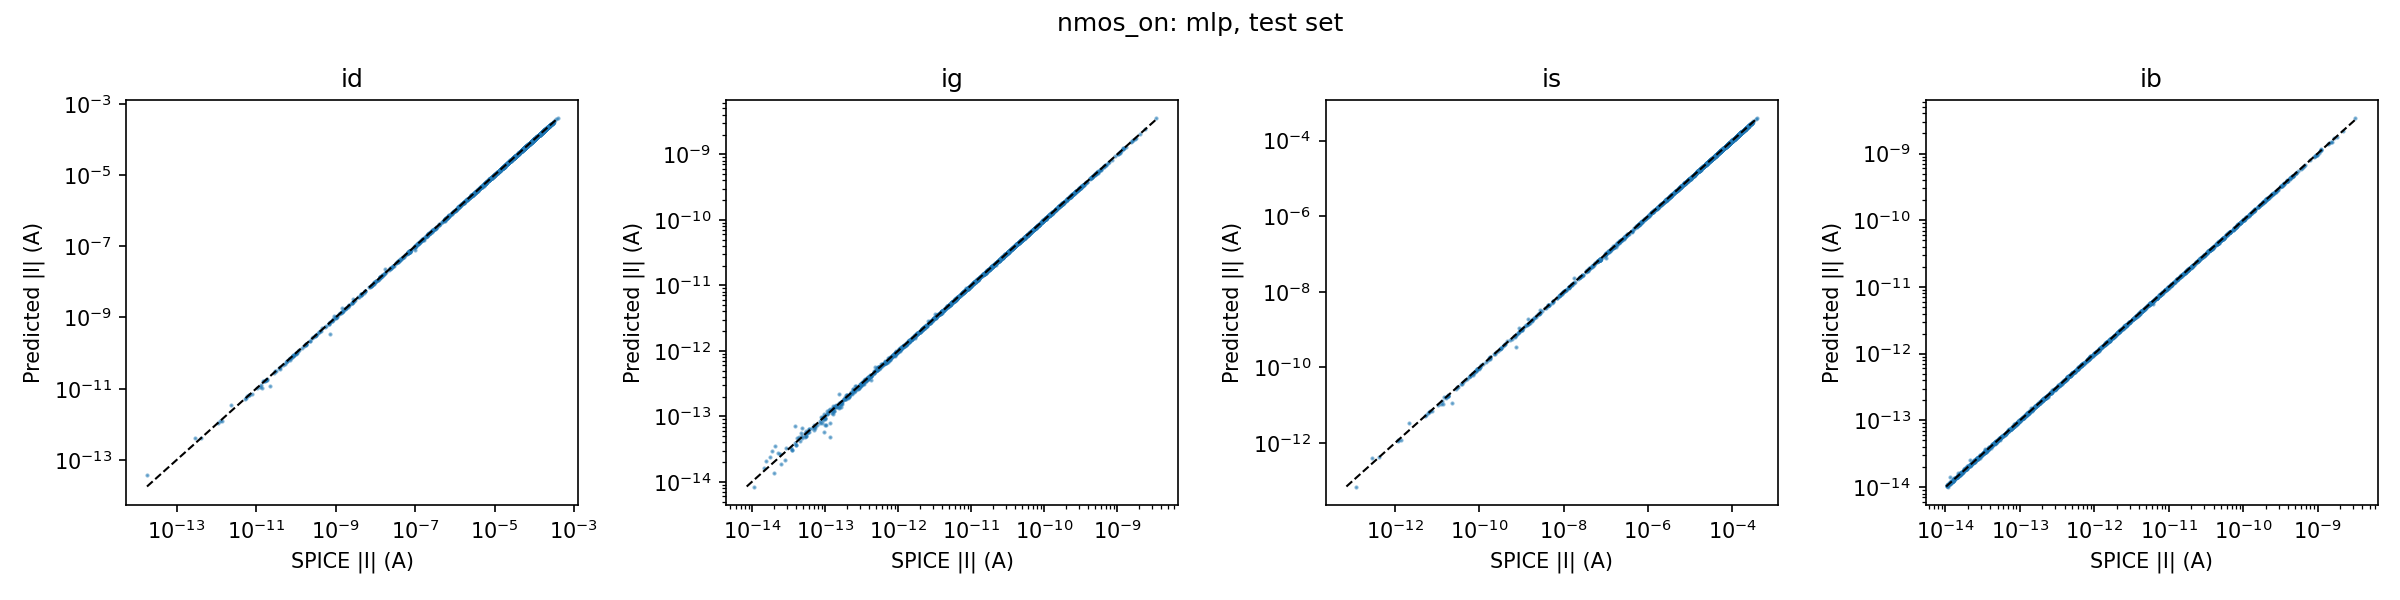

,case,model,r2_log,median_error_pct,p95_error_pct,id_r2_log,id_median_error_pct,id_p95_error_pct,ig_r2_log,ig_median_error_pct,ig_p95_error_pct,is_r2_log,is_median_error_pct,is_p95_error_pct,ib_r2_log,ib_median_error_pct,ib_p95_error_pct,sign_accuracy,max_abs_kcl_residual_A
0,nmos_off,mlp,0.997979,0.699354,5.003267,0.997277,0.746338,5.864193,0.998438,0.536389,3.19724,0.998363,0.810938,6.790354,0.997837,0.738487,4.868638,0.995833,7.880758e-24


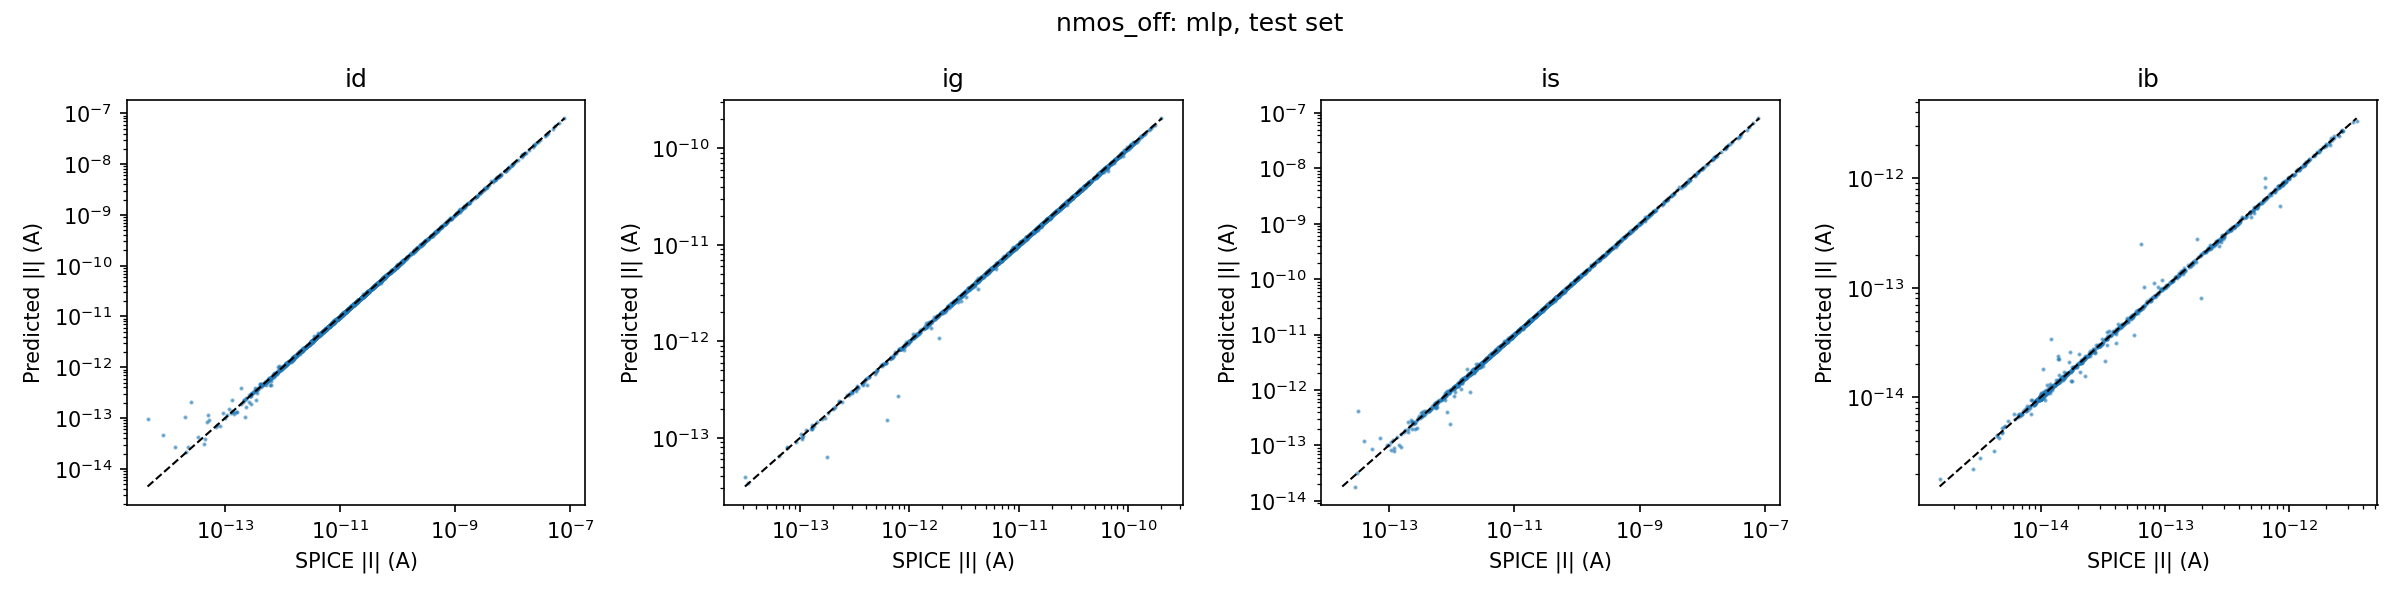

,case,model,r2_log,median_error_pct,p95_error_pct,id_r2_log,id_median_error_pct,id_p95_error_pct,ig_r2_log,ig_median_error_pct,ig_p95_error_pct,is_r2_log,is_median_error_pct,is_p95_error_pct,ib_r2_log,ib_median_error_pct,ib_p95_error_pct,sign_accuracy,max_abs_kcl_residual_A
0,pmos_on,mlp,0.999987,0.452193,2.267454,0.999985,0.475463,2.891957,0.999994,0.369277,1.328558,0.999985,0.475463,2.891956,0.999984,0.508216,2.01274,1.0,6.773865e-20


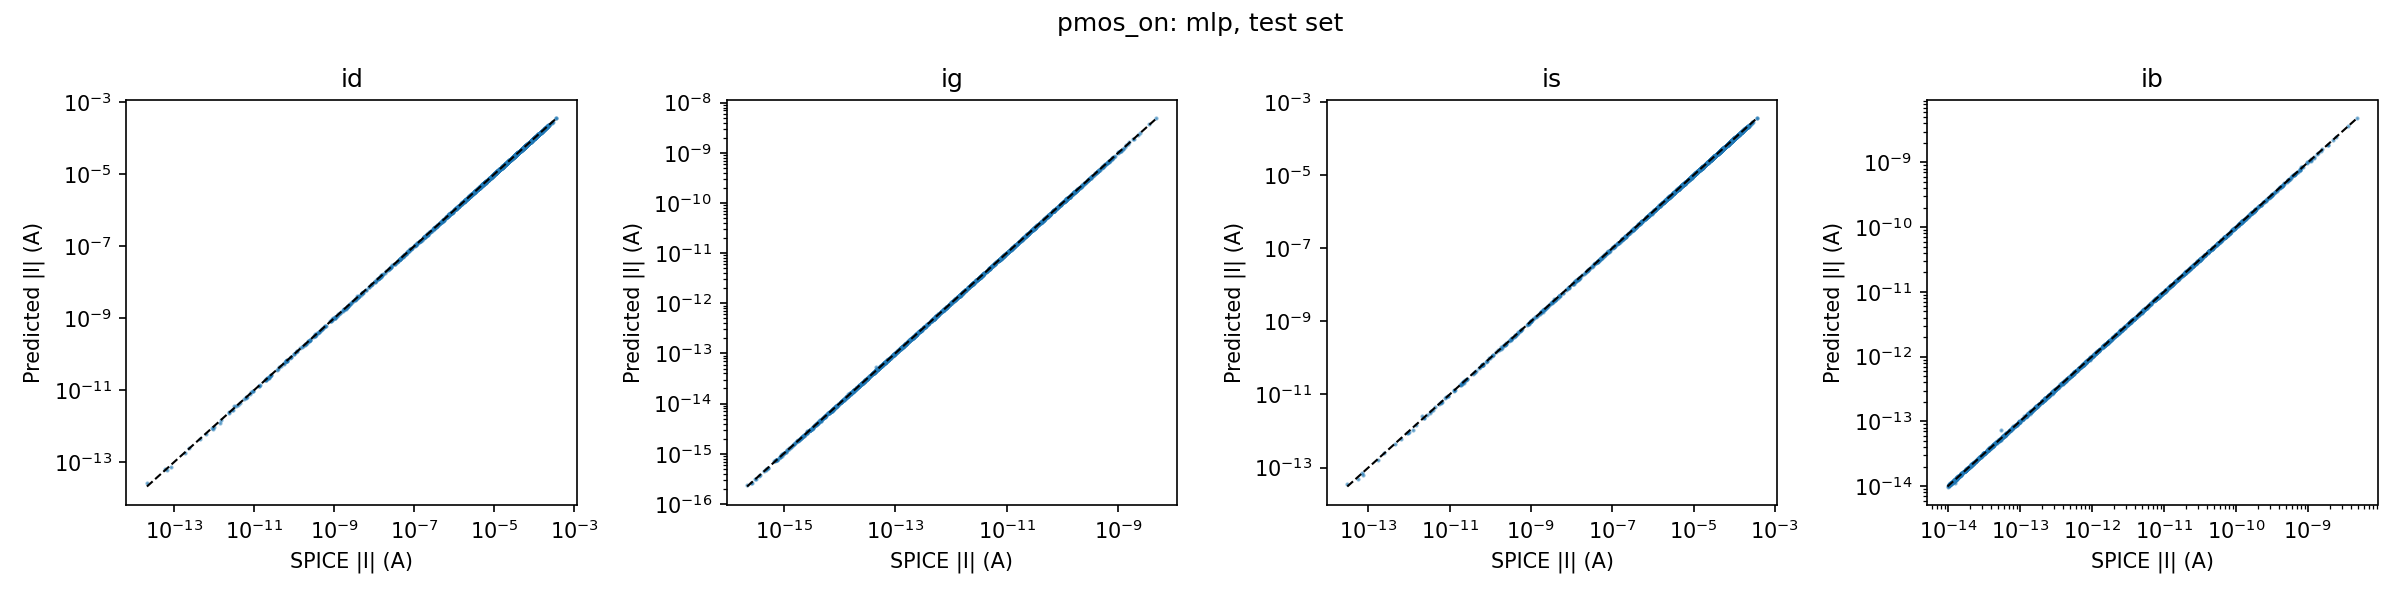

,case,model,r2_log,median_error_pct,p95_error_pct,id_r2_log,id_median_error_pct,id_p95_error_pct,ig_r2_log,ig_median_error_pct,ig_p95_error_pct,is_r2_log,is_median_error_pct,is_p95_error_pct,ib_r2_log,ib_median_error_pct,ib_p95_error_pct,sign_accuracy,max_abs_kcl_residual_A
0,pmos_off,xgb,0.835235,15.845803,305.56854,0.99034,14.40287,81.346865,0.365602,154.47875,21692.3561,0.993696,14.222698,104.601689,0.991303,3.356853,20.871732,0.9885,1.599518e-23


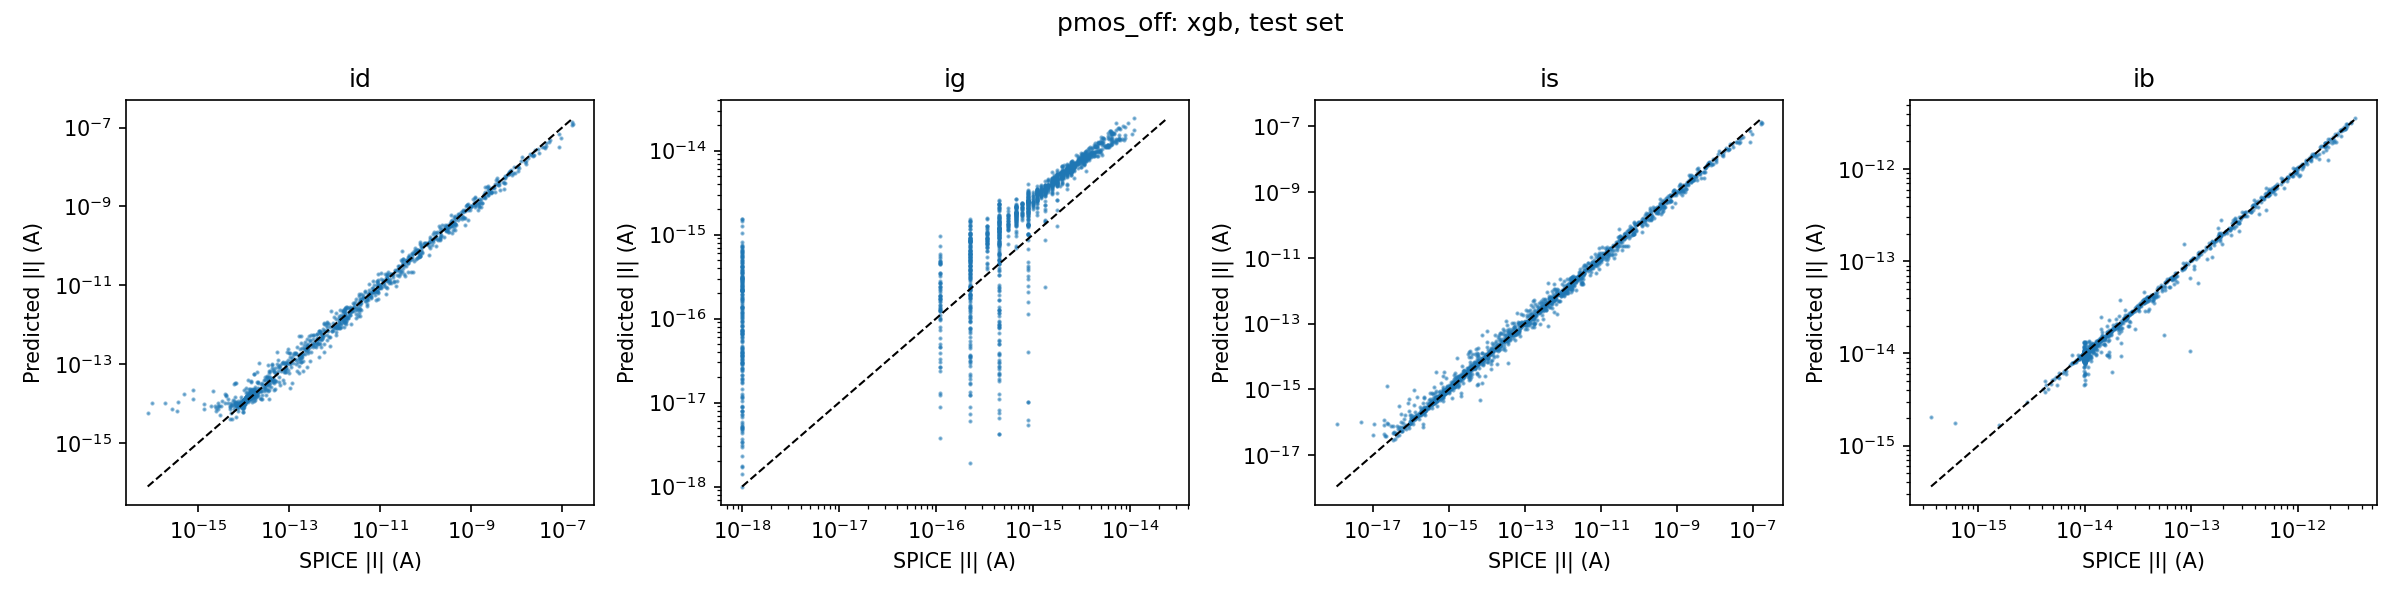

In [9]:
for k in CASES:
    display(pd.read_csv(REPO/"results"/k/"test_metrics.csv")); display(Image(REPO/"results"/k/"parity.png"))